# Testing the Classification Algorithm

## Preparations

This notebook is for testing the classification pipeline.

### Importing necessary libraries

In [1]:
import time
import asyncio

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

In [3]:
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

In [4]:
from backend.scripts.database_manager import DatabaseManager
from backend.scripts.classes import ClassManager

C:\Users\2dani\PycharmProject\ImageEmbeddings\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Connect to DB

In [5]:
db = DatabaseManager()
await db.connect()

class_manager = ClassManager(db)

Using existing database: C:\Users\2dani\PycharmProject\ImageEmbeddings\image_embeddings.sqlite
SQLite Vector extension loaded from C:\Users\2dani\PycharmProject\ImageEmbeddings\backend\.venv\Lib\site-packages\sqlite_vector\binaries\vector
Vector index built and preloaded into memory (~30 MB)


C:\Users\2dani\PycharmProject\ImageEmbeddings\backend\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


### Load dataset

Load crops with embeddings and class labels

In [6]:
rows = await db.get_crops_with_embeddings_class(page=0, page_size=2000)
print(f"Found {len(rows)} crops")

Found 1308 crops


Prepare lists for evaluation

In [7]:
crop_paths = [r['crop_path'] for r in rows]
true_labels = [r['assigned_class'] for r in rows]

In [8]:
df1 = pd.DataFrame({'crop_path': crop_paths, 'true_label': true_labels})
df1['true_label'] = df1['true_label'].astype(str)
df1

,crop_path,true_label
0,train/0/train_0/train_0_33.jpg,Frosch Reinigungsmittel
1,train/0/train_0/train_0_35.jpg,Vanish Gold
2,train/0/train_0/train_0_36.jpg,Febreze Lenor
3,train/0/train_0/train_0_38.jpg,Febreze Lenor
4,train/0/train_0/train_0_45.jpg,Denkmit Fleckenentferner Oxi Power
...,...,...
1303,train/1/train_1073/train_1073_82.jpg,Scholl Light Legs
1304,train/1/train_1073/train_1073_83.jpg,Scholl Light Legs
1305,train/1/train_1073/train_1073_84.jpg,Scholl Light Legs
1306,train/1/train_1073/train_1073_85.jpg,Scholl Light Legs


Classes ranked by instances

In [9]:
counts_df = df1.groupby('true_label').size().reset_index(name='count').sort_values('count', ascending=False)
counts_df

,true_label,count
34,Dove,111
28,Dial,99
18,Colgate,74
15,Coca Cola,64
98,Red Bull,40
...,...,...
39,E45 Wash,1
22,Colgate Whitening,1
56,Frosch Neutral Reiniger,1
37,E45 Bath,1


All classes in the dataset:

In [15]:
all_classes_1 = sorted(df1['true_label'].unique().tolist())

### Methods

In [10]:
async def classify_all(df, limit_per_class=2, threshold=0.8, concurrency=1, class_names=None):
    """
    Classifies all crops in the dataframe through the leave-one-out cross-validation algorithm.

    :param df: The dataframe to classify
    :param limit_per_class: The maximum number of crops per class to compare against
    :param threshold: The threshold to compare against
    :param concurrency: The maximum number of concurrent operations
    :param class_names: The names of the classes to consider
    :return: The dataframe with the results of the classification
    """
    sem = asyncio.Semaphore(concurrency)
    results = []

    async def _worker(crop_path, true_label):
        async with sem:
            t0 = time.perf_counter()
            res = await class_manager.classify_crop(crop_path, limit_per_class=limit_per_class, threshold=threshold, class_names=class_names)
            t1 = time.perf_counter()
            return {
                'crop_path': crop_path,
                'true_label': true_label,
                'predicted_class': res['predicted_class'],
                'confidence': res['confidence'],
                'runtime': t1 - t0
            }

    for _, row in df.iterrows():
        results.append(await _worker(row['crop_path'], row['true_label']))

    return pd.DataFrame(results)

In [12]:
def compute_classification_metrics(df_results, labels=None):
    """Compute evaluation metrics for the classification results.
    :param df_results: Classification results
    :param labels: The labels of the database
    :return: The evaluation metrics
    """
    y_true = df_results['true_label'].fillna(None).tolist()
    y_pred = df_results['predicted_class'].fillna(None).tolist()

    acc = balanced_accuracy_score(y_true, y_pred)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels,average='macro', zero_division=0)
    precision_micro, recall_micro, f1_micro, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average='micro', zero_division=0)
    report = classification_report(y_true, y_pred, labels=labels, zero_division=0, output_dict=True)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    if labels is None:
        labels = sorted(list(set(y_true) | set(y_pred)))

    return {
        'accuracy': acc,
        'precision_macro': precision_macro,
        'recall_macro': recall_macro,
        'f1_macro': f1_macro,
        'precision_micro': precision_micro,
        'recall_micro': recall_micro,
        'f1_micro': f1_micro,
        'class_report': report,
        'confusion_matrix': cm,
        'labels': labels
    }

In [13]:
def sample_classes(all_classes, db_k, query_k, overlap_ratio, seed=None):
    """
    Samples the classes into subsets of randomized query and database classes
    :param all_classes:
    :param db_k:
    :param query_k:
    :param overlap_ratio:
    :param seed:
    :return: The classes to be included in the database and query
    """
    random.seed(seed)

    # choose overlap_count
    overlap_count = int(min(db_k, query_k) * overlap_ratio)
    overlap = set(random.sample(all_classes, k=overlap_count))

    remaining = list(set(all_classes) - overlap)
    db_extra = set(random.sample(remaining, k=db_k - overlap_count))
    remaining = list(set(remaining) - db_extra)
    query_extra = set(random.sample(remaining, k=query_k - overlap_count))

    db_classes = list(overlap | db_extra)
    query_classes = list(overlap | query_extra)

    return db_classes, query_classes

## Quantitative Evaluation

For the following tests we need to classify all embeddings to compute the accuracy, recall, precision and F1-Score. \
The inputs used for limits_per_class and similarity threshold are the ones that are used on the website and app.

In [ ]:
res_df = await classify_all(df1, limit_per_class=2, threshold=0.8)
metrics = compute_classification_metrics(res_df, all_classes_1)

### Metrics at different Confidences

The confidence of the model if the query embedding belongs to certain classes is measured through the average of the cosine distance between the query embedding to the members of the class, e.g. a similarity measure between these.

To evaluate the metrics at different confidences can help us understand if there is a correlation between confidence and classification performance.
If this is the case, it is an indication that the confidence can be used as a measure of reliability for the classification results. For example, if we find that the precision is higher for predictions with higher similarity between query embedding and reference embeddings, we can use the confidence as a threshold to filter out less reliable predictions. It also provides the evidence that the similarity of two embeddings is a good measure of how likely it is that they belong to the same class, which is the underlying assumption of our classification approach.

In [175]:
df_c = res_df.copy()
df_c['predicted_class_filled'] = df_c['predicted_class'].fillna('__NO_PRED__')
df_c['true_label_filled'] = df_c['true_label'].fillna('__NO_LABEL__')

df_c['correct'] = df_c['predicted_class_filled'] == df_c['true_label_filled']

df_preds = df_c[df_c['predicted_class'].notnull()].copy()

bins = np.linspace(0.5, 1.0, 26)
df_preds['conf_bin'] = pd.cut(df_preds['confidence'], bins=bins, include_lowest=True)

precision_per_bin = (
    df_preds.groupby('conf_bin')
    .apply(lambda g: g['correct'].sum() / len(g) if len(g) > 0 else np.nan)
    .reset_index(name='precision')
)
recall_per_bin = (
    df_preds.groupby('conf_bin')
    .apply(lambda g: g['correct'].sum() / len(g) if len(g) > 0 else np.nan)
    .reset_index(name='recall')
)

f1_per_bin = (
    df_preds.groupby('conf_bin')
    .apply(lambda g: 2 * (g['correct'].sum() / len(g)) * (g['correct'].sum() / len(g)) / ((g['correct'].sum() / len(g)) + (g['correct'].sum() / len(g))) if len(g) > 0 else np.nan)
    .reset_index(name='f1')
)

bin_centers = [interval.mid for interval in precision_per_bin['conf_bin']]

Precision vs. Confidence

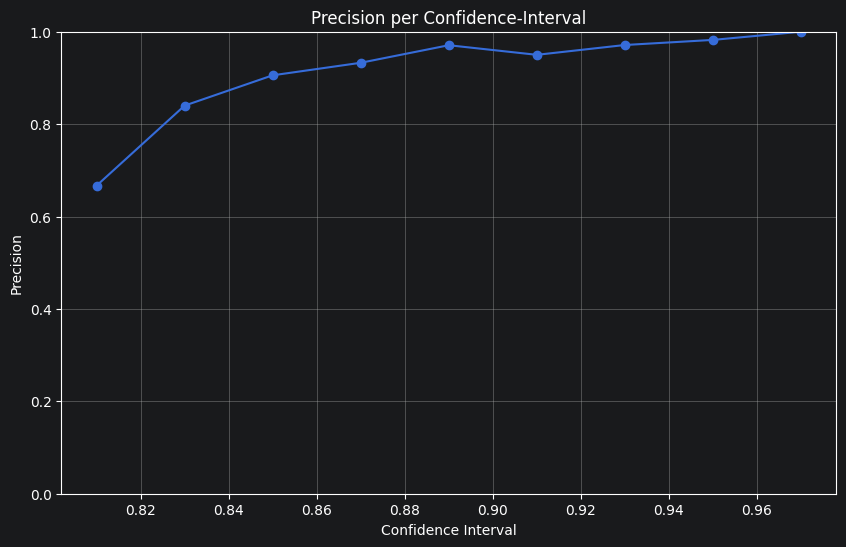

In [176]:
plt.figure(figsize=(10,6))
plt.plot(bin_centers, precision_per_bin['precision'], marker='o')
plt.xlabel('Confidence Interval')
plt.ylabel('Precision')
plt.title('Precision per Confidence-Interval')
plt.ylim(0,1)
plt.grid(True)
plt.show()

Recall vs. Confidence

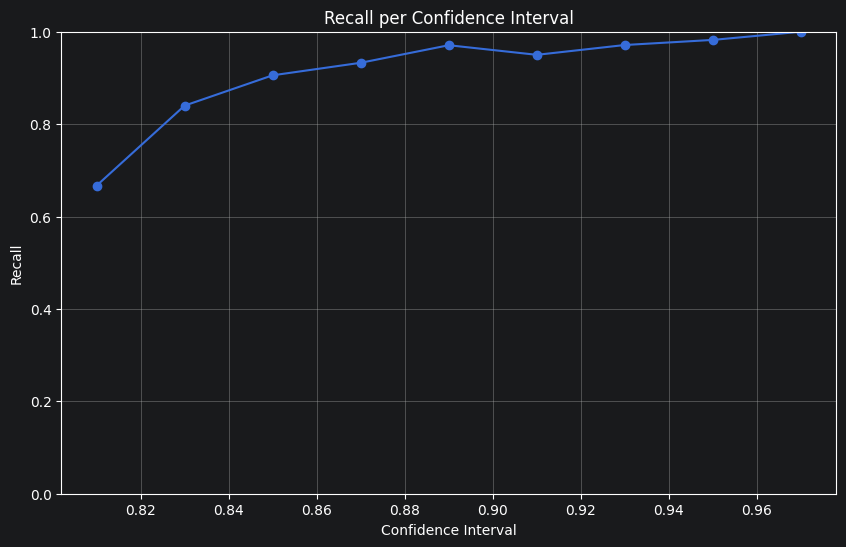

In [177]:
plt.figure(figsize=(10,6))
plt.plot(bin_centers, recall_per_bin['recall'], marker='o')
plt.xlabel('Confidence Interval')
plt.ylabel('Recall')
plt.title('Recall per Confidence Interval')
plt.ylim(0,1)
plt.grid(True)
plt.show()

F1-Score vs. Confidence

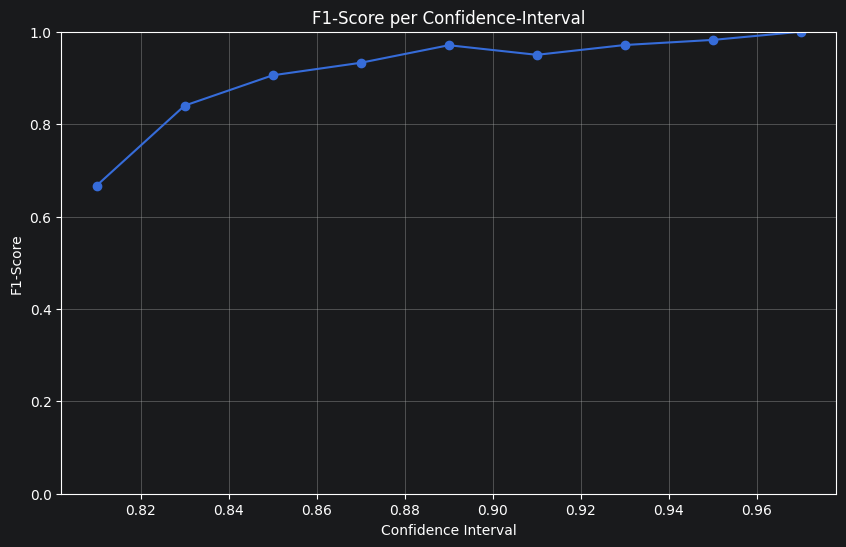

In [178]:
plt.figure(figsize=(10,6))
plt.plot(bin_centers, f1_per_bin['f1'], marker='o')
plt.xlabel('Confidence Interval')
plt.ylabel('F1-Score')
plt.title('F1-Score per Confidence-Interval')
plt.ylim(0,1)
plt.grid(True)
plt.show()

### Metrics at different Similarity Thresholds with randomized data

The Similarity Threshold determines how strict the classification is. We will evaluate the metrics at different threshold values to see how it affects the performance.
The threshold is a value between 0 and 1 that determines how similar a crop must be to the reference class examples to be classified as that class. A higher threshold means that the crop must be more similar to the reference examples to be classified as that class, which can lead to higher precision but lower recall. A lower threshold means that the crop can be less similar to the reference examples to be classified as that class, which can lead to higher recall but lower precision.

We compute the classification of all crops in the dataframe with an initial threshold of 0, to reduce compution.
The input used for limits_per_class is the one that is used on the website and app.

The optimal threshold can be determined by analyzing the precision-recall tradeoff.

To explore where the best values for both lie, it is necessary to not only evaluate them with an indifferent other value but to evaluate them both simultaneously.

The other tested with the correct product is in the dataset, but in the real world either the product that was searched for could not appear in the frame or could be not evalauated due to time constraints or the detector not proposing all regions correctly. This is an attempt to produce a better test for the metrics at different Number of Reference Embeddings and at different Thresholds.

Here we randomize the classes searched for and the classes that are used as reference.

We apply the thresholds manually, compute the metrics and save them for each iteration.

In [16]:
thresholds = np.arange(0.7, 0.95, 0.01).tolist()
ref_class_sizes = np.arange(2, 12, 2).tolist()
n_seeds = 3

n_t = len(thresholds)
n_k = len(ref_class_sizes)
accuracies_ctr = np.full((n_t, n_k), np.nan)
precisions_micro_ctr = np.full((n_t, n_k), np.nan)
recalls_micro_ctr = np.full((n_t, n_k), np.nan)
f1score_micro_ctr = np.full((n_t, n_k), np.nan)
precisions_macro_ctr = np.full((n_t, n_k), np.nan)
recalls_macro_ctr = np.full((n_t, n_k), np.nan)
f1score_macro_ctr = np.full((n_t, n_k), np.nan)


for j, ref_class_size in enumerate(ref_class_sizes):
    accuracies_by_threshold = [[] for _ in range(n_t)]
    precisions_micro_by_threshold = [[] for _ in range(n_t)]
    recalls_micro_by_threshold = [[] for _ in range(n_t)]
    f1_micro_by_threshold = [[] for _ in range(n_t)]
    precisions_macro_by_threshold = [[] for _ in range(n_t)]
    recalls_macro_by_threshold = [[] for _ in range(n_t)]
    f1_macro_by_threshold = [[] for _ in range(n_t)]

    for seed in range(n_seeds):
        # Sample dataframe and classes to have a mix of classes that are only partly the same
        selected_classes_db_r, selected_classes_query_r = sample_classes(all_classes_1, db_k=70, query_k=35, overlap_ratio=0.4, seed=seed)
        combined_classes_r =  sorted(selected_classes_db_r + selected_classes_query_r)

        df_subset_r =  df1[df1['true_label'].isin(selected_classes_query_r)].reset_index(drop=True)
        res_r = await classify_all(df_subset_r, limit_per_class=ref_class_size, threshold=0, class_names=selected_classes_db_r)

        for i, threshold in enumerate(thresholds):
            # Apply Thresholds to results
            res_r['predicted_at_t'] = res_r.apply(lambda r: r['predicted_class'] if r['confidence'] >= threshold else None, axis=1)
            df_eval_r = res_r.copy()

            # If the class of the crop queried is not in the database, the true label should be 'Unknown'
            db_classes = set(selected_classes_db_r)
            df_eval_r['true_label'] = df_eval_r['true_label'].apply(lambda lbl: lbl if lbl in db_classes else None)

            df_eval_r['predicted_class'] = df_eval_r['predicted_at_t']
            metrics_r = compute_classification_metrics(df_eval_r, combined_classes_r)

            accuracies_by_threshold[i].append(metrics_r.get('accuracy', np.nan))
            precisions_micro_by_threshold[i].append(metrics_r.get('precision_micro', np.nan))
            recalls_micro_by_threshold[i].append(metrics_r.get('recall_micro', np.nan))
            f1_micro_by_threshold[i].append(metrics_r.get('f1_micro', np.nan))
            precisions_macro_by_threshold[i].append(metrics_r.get('precision_macro', np.nan))
            recalls_macro_by_threshold[i].append(metrics_r.get('recall_macro', np.nan))
            f1_macro_by_threshold[i].append(metrics_r.get('f1_macro', np.nan))

    for i in range(n_t):
        accuracies_ctr[i, j] = float(np.mean(accuracies_by_threshold))

        # Micro averaged
        precisions_micro_ctr[i, j] = float(np.mean(precisions_micro_by_threshold))
        recalls_micro_ctr[i, j] = float(np.mean(recalls_micro_by_threshold))
        f1score_micro_ctr[i, j] = float(np.mean(f1_micro_by_threshold))

        # Macro Averaged
        precisions_macro_ctr[i, j] = float(np.mean(precisions_macro_by_threshold))
        recalls_macro_ctr[i, j] = float(np.mean(recalls_macro_by_threshold))
        f1score_macro_ctr[i, j] = float(np.mean(f1_macro_by_threshold))

ValueError: Classification metrics can't handle a mix of multiclass and unknown targets

#### Accuracy vs. Number of Embeddings & Threshold

In [ ]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, accuracies_ctr[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('Accuracy')
plt.title('Accuracy-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

#### Precision vs. Number of Embeddings & Threshold

Precision (micro)

In [ ]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, precisions_micro_ctr[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('Precision (micro)')
plt.title('Precision-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

Precision (macro)

In [ ]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, precisions_macro_ctr[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('Precision (macro)')
plt.title('Precision-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

#### Recall vs. Number of Embeddings & Threshold

Recall (micro)

In [ ]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, recalls_micro_ctr[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('Recall (micro)')
plt.title('Recall-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

Recall (macro)

In [ ]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, recalls_macro_ctr[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('Recall (macro)')
plt.title('Recall-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

#### F1-Score vs. Number of Embeddings & Threshold

F1-Score (micro)

In [ ]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, f1score_micro_ctr[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('F1-Score (micro)')
plt.title('F1-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

F1-Score (macro)

In [ ]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, f1score_macro_ctr[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('F1-Score (macro)')
plt.title('F1-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()